# Lab 5. Transfer Learning

## Overview
Multi-class image classification (10 classes) using transfer learning.

Two approaches are implemented and compared:
1. **Feature Extraction**: freeze the base model, train only the new classification layers.
2. **Fine-Tuning**: unfreeze some top layers of the base model and continue training.

**Steps in this notebook**
0. Setup and config
1. Dataset (load, 80/20 split, inspect)
2. Input pipeline (prefetch, augmentation, preprocessing)
3. Model (pre-trained base + new head, architecture diagram)
4. Approach 1: Feature Extraction
5. Approach 2: Fine-Tuning
6. Compare both methods (accuracy and training time)
7. Report checklist and submission

## 0. Setup

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: []


In [ ]:
DATA_DIR   = "F:/SwinburneCourse/COS30082 - Applied ML/COS30082/Lab/05/Animals and Plants Dataset/train"
IMG_SIZE   = (160, 160)
BATCH_SIZE = 32
VAL_SPLIT  = 0.2        # 80/20 split
SEED       = 42
NUM_CLASSES = 10

FE_EPOCHS  = 10         # feature extraction epochs
FT_EPOCHS  = 10         # extra epochs for fine-tuning
BASE_LR    = 1e-4
FINE_TUNE_AT = 100      # layers before this index stay frozen in fine-tuning

tf.keras.utils.set_random_seed(SEED)

## 1. Dataset
The `train` folder has 10,000 images across 10 classes (1,000 per class). The `test` folder is not used.

`image_dataset_from_directory` expects **one sub-folder per class**:
```
train/
  class_a/ img1.jpg ...
  class_b/ ...
```
If your `train` folder is flat (all images in one folder with a CSV of labels), you need to sort the images into class folders first.

In [3]:
assert os.path.isdir(DATA_DIR), f"Folder not found: {DATA_DIR}"

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=VAL_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=VAL_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

class_names = train_ds.class_names
print("Classes:", class_names)
assert len(class_names) == NUM_CLASSES, f"Expected {NUM_CLASSES} classes, found {len(class_names)}"
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val batches:  ", tf.data.experimental.cardinality(val_ds).numpy())

Found 5006 files belonging to 10 classes.
Using 4005 files for training.
Found 5006 files belonging to 10 classes.
Using 1001 files for validation.
Classes: ['Amphibia', 'Animalia', 'Arachnida', 'Aves', 'Fungi', 'Insecta', 'Mammalia', 'Mollusca', 'Plantae', 'Reptilia']
Train batches: 126
Val batches:   32


Show the first nine training images and labels.

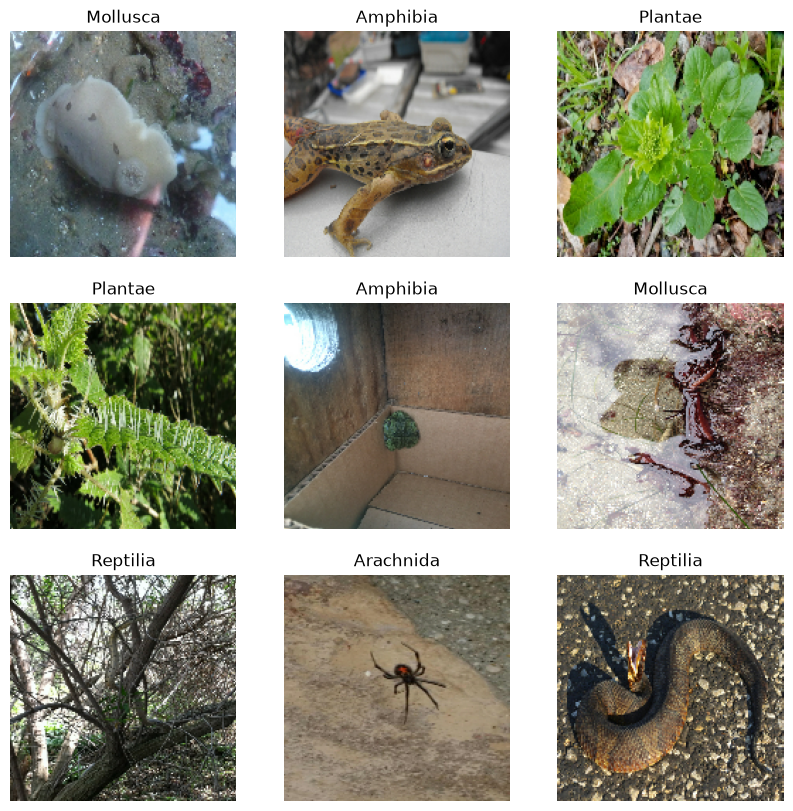

In [4]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

## 2. Input pipeline

### Prefetch (avoid I/O blocking)

In [5]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds   = val_ds.prefetch(buffer_size=AUTOTUNE)

### Data augmentation
Random transformations on training images reduce overfitting. These layers are active only during training.

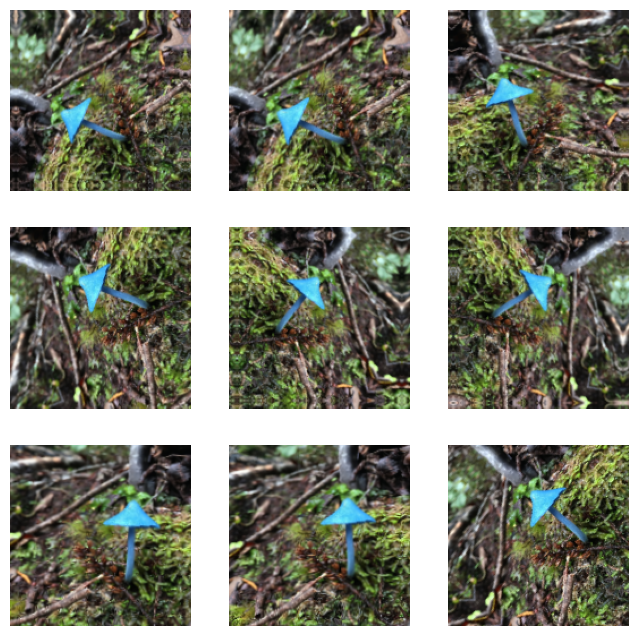

In [6]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

for images, _ in train_ds.take(1):
    plt.figure(figsize=(8, 8))
    first_image = images[0]
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        aug = data_augmentation(tf.expand_dims(first_image, 0))
        plt.imshow(aug[0].numpy().astype("uint8"))
        plt.axis("off")
    plt.show()

## 3. Model
**Pre-trained model used: MobileNetV2** (trained on ImageNet, 1.4M images, 1000 classes).

You can swap it for another network (for example `ResNet50` or `EfficientNetB0`). If you do, use the matching `preprocess_input` from the same module.

Architecture:
`Input -> Augmentation -> preprocess_input -> MobileNetV2 (no top) -> GlobalAveragePooling2D -> Dropout -> Dense(10)`

In [7]:
IMG_SHAPE = IMG_SIZE + (3,)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights="imagenet",
)
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input  # scales pixels to [-1, 1]

# Check what the base model outputs for one batch
image_batch, label_batch = next(iter(train_ds))
print("Base model output:", base_model(image_batch).shape)  # (batch, 5, 5, 1280) for 160x160

Base model output: (32, 5, 5, 1280)


### Build the full model

In [8]:
inputs = tf.keras.Input(shape=IMG_SHAPE)
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)          # keep BatchNorm in inference mode
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES)(x)   # logits, no activation
model = tf.keras.Model(inputs, outputs, name="transfer_model")

model.summary()

Model: "transfer_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 2,236,682 (8.53 MB)

 Non-trainable params: 34,112 (133.25 KB)

### Architecture diagram (use this image in the report)

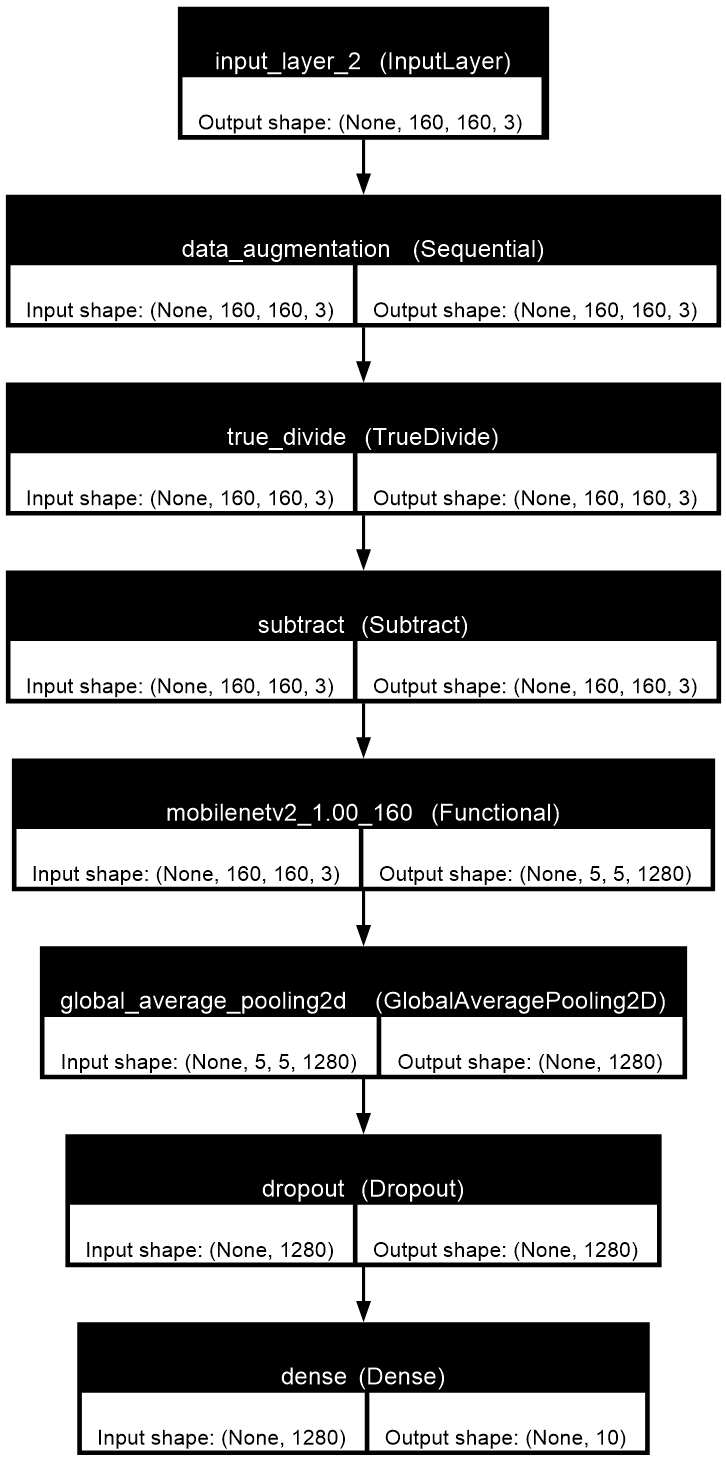

In [9]:
import pydot
import graphviz

try:
    from IPython.display import Image, display
    tf.keras.utils.plot_model(model, to_file="model_architecture.png",
                              show_shapes=True, show_layer_names=True, dpi=110)
    display(Image("model_architecture.png"))
except Exception as e:
    print("plot_model needs pydot and graphviz. Error:", e)
    print("Fix: pip install pydot  (and install graphviz), or draw the diagram by hand from model.summary().")

### Helpers
Functions to plot learning curves and read results.

In [10]:
def plot_curves(acc, val_acc, loss, val_loss, title, split_at=None):
    plt.figure(figsize=(9, 8))
    plt.subplot(2, 1, 1)
    plt.plot(acc, label="Training Accuracy")
    plt.plot(val_acc, label="Validation Accuracy")
    if split_at is not None:
        plt.axvline(split_at - 1, color="gray", linestyle="--", label="Start Fine-Tuning")
    plt.ylabel("Accuracy"); plt.legend(loc="lower right"); plt.title(title + " - Accuracy")

    plt.subplot(2, 1, 2)
    plt.plot(loss, label="Training Loss")
    plt.plot(val_loss, label="Validation Loss")
    if split_at is not None:
        plt.axvline(split_at - 1, color="gray", linestyle="--", label="Start Fine-Tuning")
    plt.ylabel("Loss"); plt.xlabel("epoch"); plt.legend(loc="upper right"); plt.title(title + " - Loss")
    plt.tight_layout(); plt.show()

def count_params(m):
    trainable = int(sum(np.prod(v.shape) for v in m.trainable_variables))
    total = int(m.count_params())
    return trainable, total

results = {}   # filled in the next sections

## 4. Approach 1: Feature Extraction
Freeze the whole base model. Only the new head (`Dense` layer) is trained.

In [11]:
base_model.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=BASE_LR),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

fe_trainable, fe_total = count_params(model)
print(f"Trainable params: {fe_trainable:,} / {fe_total:,}")

loss0, acc0 = model.evaluate(val_ds, verbose=0)
print(f"Before training -> val loss: {loss0:.3f}, val acc: {acc0:.3f}")

Trainable params: 12,810 / 2,270,794
Before training -> val loss: 2.009, val acc: 0.296


In [12]:
t0 = time.perf_counter()
history_fe = model.fit(train_ds, epochs=FE_EPOCHS, validation_data=val_ds)
fe_time = time.perf_counter() - t0
print(f"\nFeature extraction training time: {fe_time:.1f} s")

Epoch 1/10


c:\Users\Admin\anaconda3\envs\COS30082Lab\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


126/126 ━━━━━━━━━━━━━━━━━━━━ 22s 151ms/step - accuracy: 0.1680 - loss: 2.4953 - val_accuracy: 0.3497 - val_loss: 1.9409
Epoch 2/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 19s 151ms/step - accuracy: 0.3101 - loss: 2.0395 - val_accuracy: 0.4555 - val_loss: 1.6949
Epoch 3/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 18s 144ms/step - accuracy: 0.4052 - loss: 1.7568 - val_accuracy: 0.5115 - val_loss: 1.5363
Epoch 4/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 19s 151ms/step - accuracy: 0.4699 - loss: 1.5860 - val_accuracy: 0.5285 - val_loss: 1.4869
Epoch 5/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 20s 156ms/step - accuracy: 0.5059 - loss: 1.4940 - val_accuracy: 0.5504 - val_loss: 1.3897
Epoch 6/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 19s 148ms/step - accuracy: 0.5276 - loss: 1.4129 - val_accuracy: 0.5624 - val_loss: 1.3384
Epoch 7/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 20s 161ms/step - accuracy: 0.5586 - loss: 1.3458 - val_accuracy: 0.5774 - val_loss: 1.2952
Epoch 8/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 21s 164ms/step - accuracy: 0.5743 - loss: 1.3022 - val

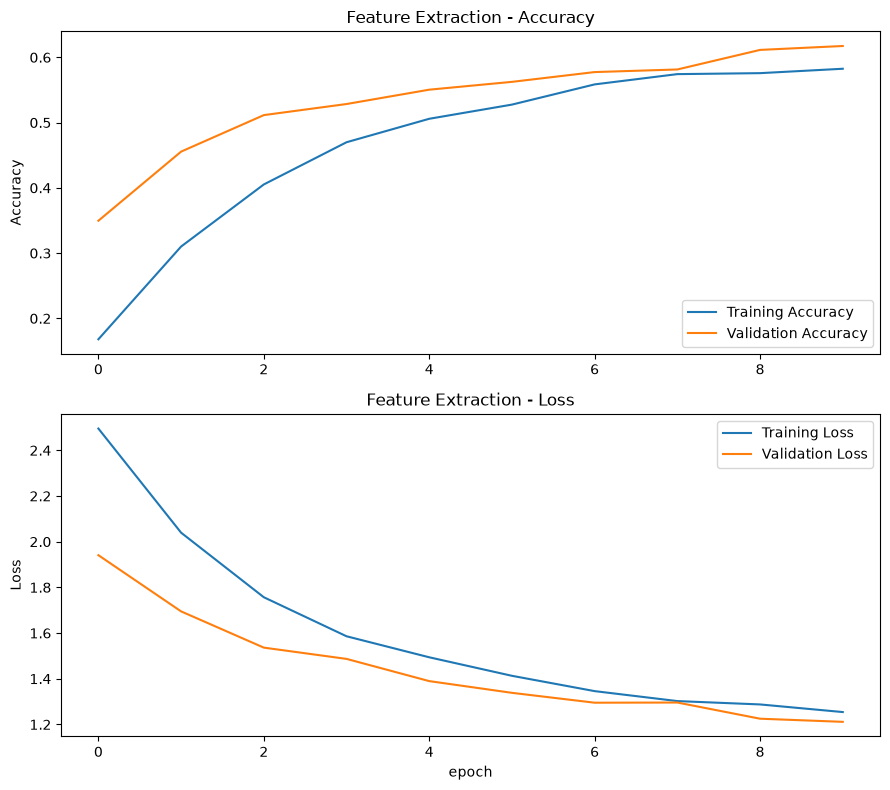

In [13]:
h = history_fe.history
plot_curves(h["accuracy"], h["val_accuracy"], h["loss"], h["val_loss"], "Feature Extraction")

results["Feature Extraction"] = {
    "Val accuracy": h["val_accuracy"][-1],
    "Val loss": h["val_loss"][-1],
    "Train accuracy": h["accuracy"][-1],
    "Epochs": FE_EPOCHS,
    "Training time (s)": fe_time,
    "Trainable params": fe_trainable,
}

## 5. Approach 2: Fine-Tuning
Unfreeze the top layers of the base model and continue training the model from Section 4.
Use a **lower learning rate** (here 10x lower) so the pre-trained weights are only adjusted slightly.

In [14]:
base_model.trainable = True
print("Layers in base model:", len(base_model.layers))

# Freeze everything before FINE_TUNE_AT, keep the top layers trainable
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=BASE_LR / 10),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

ft_trainable, ft_total = count_params(model)
print(f"Trainable params: {ft_trainable:,} / {ft_total:,}")

Layers in base model: 154
Trainable params: 1,874,250 / 2,270,794


In [15]:
total_epochs = FE_EPOCHS + FT_EPOCHS

t0 = time.perf_counter()
history_ft = model.fit(
    train_ds,
    epochs=total_epochs,
    initial_epoch=FE_EPOCHS,      # continue from where Section 4 stopped
    validation_data=val_ds,
)
ft_time = time.perf_counter() - t0
print(f"\nFine-tuning training time (extra): {ft_time:.1f} s")

Epoch 11/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 34s 200ms/step - accuracy: 0.4697 - loss: 1.6098 - val_accuracy: 0.6593 - val_loss: 1.0701
Epoch 12/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 22s 174ms/step - accuracy: 0.5358 - loss: 1.4038 - val_accuracy: 0.6803 - val_loss: 1.0019
Epoch 13/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 23s 182ms/step - accuracy: 0.5738 - loss: 1.2783 - val_accuracy: 0.7013 - val_loss: 0.9590
Epoch 14/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 26s 209ms/step - accuracy: 0.5885 - loss: 1.2559 - val_accuracy: 0.7093 - val_loss: 0.9398
Epoch 15/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 26s 210ms/step - accuracy: 0.6122 - loss: 1.1749 - val_accuracy: 0.7133 - val_loss: 0.9202
Epoch 16/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 29s 230ms/step - accuracy: 0.6262 - loss: 1.1576 - val_accuracy: 0.7333 - val_loss: 0.8885
Epoch 17/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 30s 235ms/step - accuracy: 0.6335 - loss: 1.1074 - val_accuracy: 0.7433 - val_loss: 0.8526
Epoch 18/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 29s 230ms/step - accuracy: 0.6360 -

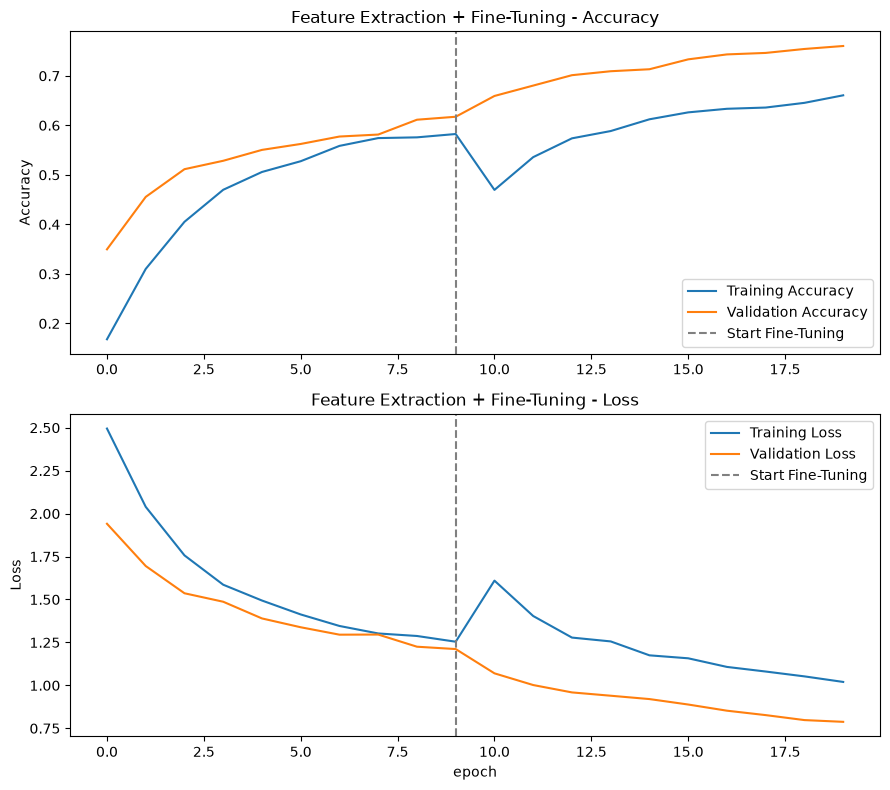

In [16]:
hf = history_ft.history
acc      = h["accuracy"]     + hf["accuracy"]
val_acc  = h["val_accuracy"] + hf["val_accuracy"]
loss     = h["loss"]         + hf["loss"]
val_loss = h["val_loss"]     + hf["val_loss"]

plot_curves(acc, val_acc, loss, val_loss, "Feature Extraction + Fine-Tuning", split_at=FE_EPOCHS)

results["Fine-Tuning"] = {
    "Val accuracy": hf["val_accuracy"][-1],
    "Val loss": hf["val_loss"][-1],
    "Train accuracy": hf["accuracy"][-1],
    "Epochs": FT_EPOCHS,
    "Training time (s)": ft_time,
    "Trainable params": ft_trainable,
}

## 6. Comparison: Feature Extraction vs Fine-Tuning
Fine-tuning starts from the feature-extraction model, so its **total** cost is the sum of both phases.

In [17]:
df = pd.DataFrame(results).T
df.loc["Fine-Tuning (total, FE + FT)"] = {
    "Val accuracy": results["Fine-Tuning"]["Val accuracy"],
    "Val loss": results["Fine-Tuning"]["Val loss"],
    "Train accuracy": results["Fine-Tuning"]["Train accuracy"],
    "Epochs": FE_EPOCHS + FT_EPOCHS,
    "Training time (s)": fe_time + ft_time,
    "Trainable params": ft_trainable,
}
display_df = df.copy()
display_df["Val accuracy"] = (display_df["Val accuracy"] * 100).round(2).astype(str) + " %"
display_df["Train accuracy"] = (display_df["Train accuracy"] * 100).round(2).astype(str) + " %"
display_df["Val loss"] = display_df["Val loss"].round(4)
display_df["Training time (s)"] = display_df["Training time (s)"].round(1)
display_df

,Val accuracy,Val loss,Train accuracy,Epochs,Training time (s),Trainable params
Feature Extraction,61.74 %,1.2114,58.25 %,10.0,195.0,12810.0
Fine-Tuning,76.02 %,0.7877,66.07 %,10.0,285.1,1874250.0
"Fine-Tuning (total, FE + FT)",76.02 %,0.7877,66.07 %,20.0,480.2,1874250.0


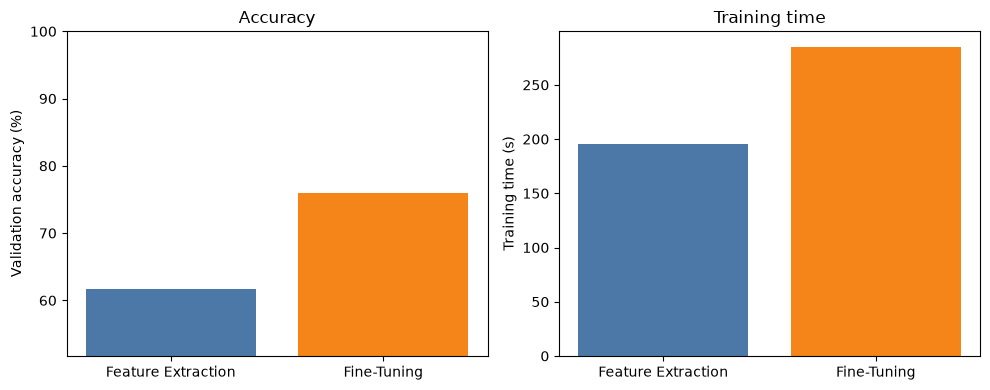

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
names = ["Feature Extraction", "Fine-Tuning"]

ax[0].bar(names, [results[n]["Val accuracy"] * 100 for n in names], color=["#4C78A8", "#F58518"])
ax[0].set_ylabel("Validation accuracy (%)"); ax[0].set_title("Accuracy")
lo = min(results[n]["Val accuracy"] for n in names) * 100
ax[0].set_ylim(max(0, lo - 10), 100)

ax[1].bar(names, [results[n]["Training time (s)"] for n in names], color=["#4C78A8", "#F58518"])
ax[1].set_ylabel("Training time (s)"); ax[1].set_title("Training time")
plt.tight_layout(); plt.show()

In [19]:
fe, ft = results["Feature Extraction"], results["Fine-Tuning"]
diff = (ft["Val accuracy"] - fe["Val accuracy"]) * 100
print(f"Feature Extraction: val acc {fe['Val accuracy']*100:.2f}%, time {fe['Training time (s)']:.1f}s, trainable params {fe['Trainable params']:,}")
print(f"Fine-Tuning:        val acc {ft['Val accuracy']*100:.2f}%, time {ft['Training time (s)']:.1f}s (extra), trainable params {ft['Trainable params']:,}")
print(f"Accuracy change from fine-tuning: {diff:+.2f} points")
print(f"Total time (FE + FT): {fe['Training time (s)'] + ft['Training time (s)']:.1f}s")

Feature Extraction: val acc 61.74%, time 195.0s, trainable params 12,810
Fine-Tuning:        val acc 76.02%, time 285.1s (extra), trainable params 1,874,250
Accuracy change from fine-tuning: +14.29 points
Total time (FE + FT): 480.2s


## 7. Report and submission

**Report (1 page)** must include:
- [ ] The pre-trained model used: MobileNetV2 (ImageNet weights), or the one you chose
- [ ] Your model architecture diagram: `model_architecture.png` (saved by Section 3)
- [ ] Comparison of feature extraction vs fine-tuning: the table and charts from Section 6, plus 2-3 sentences on accuracy and training time

**Things to mention in the comparison**
- Which method got higher validation accuracy, and by how much
- Training time per method, and the total cost of fine-tuning (FE + FT)
- Trainable parameters in each method
- Any overfitting seen in the curves (gap between training and validation)

**Submission:** submit this notebook and the report on Canvas, then demonstrate to the tutor in the lab session.